# Neural Network from Scratch: MNIST Digit Classifier (NumPy)

A fully-connected neural network (MLP) built **from scratch with NumPy only**: no autograd, no `torch.nn`. Initialization, forward pass, loss, backpropagation, optimizers (SGD and Adam), the training loop, evaluation and model saving are all hand-written. (`torchvision` is used only to download MNIST.)

**Headline result:** a 109,386-parameter network reaches **97.65% test accuracy**, with a backward pass verified by gradient checking.

**Notebook outline**

0. Setup
1. Data preprocessing
2. Model architecture and forward pass
3. Loss and accuracy
4. Backpropagation and gradient check
5. Optimizers and the "overfit a tiny subset" test
6. Full training loop
7. Evaluation on the test set
8. Saving and loading the model
9. SGD vs Adam
10. Conclusions and next steps

**How the code is organized.** This notebook is the *driver*. The implementations live in small modules inside the `Neural_networks` folder and are loaded with `%run`:

| Module | What it provides |
|---|---|
| `data_preprocessing.py` | load MNIST, flatten and scale, train/validation split, standardize, one-hot labels, `batch_generator` |
| `model_architecture.py` | `layers_size`, `init_params` (He init), `relu`, `softmax`, `forward` |
| `loss_and_accuracy.py` | `cross_entropy`, `accuracy` |
| `backpropagation.py` | `backward`, `grad_check` |
| `optimizers.py` | `SGD`, `Adam` |
| `training_loop.py` | `evaluate`, `train` |
| `load_model.py` | `load_model` |

> **Label convention used everywhere:** lowercase `y_*` are **integer** labels (used for accuracy and the confusion matrix); uppercase `Y_*` are **one-hot** labels (used for the loss and the gradient).

---
## 0. Setup

Mount Google Drive (where the project modules are stored), add the folder to Python's path, and import the libraries used directly in this notebook. NumPy does all the math; Matplotlib draws the plots.

In [1]:
# Mount Google Drive: the project modules (.py files) live in MyDrive/Neural_networks
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Make the project folder importable
import sys
sys.path.append('/content/drive/MyDrive/Neural_networks')

In [3]:
import copy                      # deep-copying weights (best-checkpoint snapshots)
import numpy as np               # all the math: arrays, matrix multiplies, random numbers
import matplotlib.pyplot as plt  # learning curves and diagnostic plots

---
## 1. Data preprocessing

`data_preprocessing.py` prepares everything the network consumes. Each step and the reason for it:

| Step | Why |
|---|---|
| Load MNIST (60,000 train / 10,000 test images) | standard benchmark of 28×28 grayscale digits |
| Flatten each image to 784 values, scale pixels to [0, 1] | an MLP takes vectors; small inputs keep activations well-behaved |
| Shuffle (fixed seed) and split train into **55,000 train / 5,000 validation** | validation is for picking checkpoints and hyperparameters; the test set stays untouched until the very end |
| Standardize with the **train** mean and std only | zero-centered inputs train faster with ReLU + He init; using train-only statistics avoids leaking validation/test information |
| Keep integer labels (`y_*`) **and** one-hot labels (`Y_*`) | one-hot for the loss and gradient, integers for accuracy and the confusion matrix |
| `batch_generator(X, Y, bs)` | reshuffles every epoch and yields mini-batches (the last batch is smaller, which is fine because the loss is averaged by the actual batch size) |

The cell below checks shapes, that the standardized data has mean about 0 and std about 1, that the classes are balanced (each roughly 9 to 11%), and that a batch has the expected shape.

In [4]:
# Run the data-prep script. It defines: X_train / X_valid / X_test (inputs),
# y_* (integer labels), Y_* (one-hot labels), mean / std (train statistics) and batch_generator
%run /content/drive/MyDrive/Neural_networks/data_preprocessing.py

In [5]:
# Sanity checks on the prepared data
print(X_train.shape, Y_train.shape, X_valid.shape, Y_valid.shape)  # expect (55000,784) (55000,10) (5000,784) (5000,10)
print(X_train.mean(), X_train.std())                               # standardized: mean ~ 0, std ~ 1
print(np.bincount(y_train) / len(y_train))                         # class balance (each ~0.09-0.11); needs INTEGER labels
xb, yb = next(batch_generator(X_train, y_train))                   # integer labels here only to check the batch shapes
print(xb.shape, yb.shape)                                          # expect (128, 784) (128,)

(55000, 784) (55000, 10) (5000, 784) (5000, 10)
2.326753e-08 1.0000001
[0.09832727 0.11158182 0.09898182 0.10212727 0.09803636 0.09014545
 0.09918182 0.10463636 0.0976     0.09938182]
(128, 784) (128,)


---
## 2. Model architecture and forward pass

**784 → 128 → 64 → 10**, with ReLU on the hidden layers and softmax on the output.

- **Parameters:** 784·128 + 128 = 100,480, then 128·64 + 64 = 8,256, then 64·10 + 10 = 650, for **109,386** in total.
- **He initialization:** `W ~ N(0, 2 / fan_in)`, biases start at zero. Random weights break the symmetry between neurons, and the `2 / fan_in` scale keeps activation variance roughly constant through ReLU layers so signals neither explode nor vanish.
- **Forward pass:** per layer `z = a_prev @ W + b`, then `a = relu(z)` (hidden) or `softmax(z)` (output). Softmax subtracts the row maximum first so `exp` cannot overflow. Every `z` and `a` is stored in a `cache` because backpropagation needs them.
- **Why `W` is `(fan_in, fan_out)`:** a batch of shape `(batch, fan_in)` times `W` gives `(batch, fan_out)` with no transposes, so the whole batch is processed in a single matrix multiply.

**Checks in the next cell:** parameter shapes, probabilities of shape `(128, 10)` whose rows sum to 1, no NaNs, and the initial loss. A 10-class model that guesses uniformly has loss ln(10) ≈ 2.30. We measure about 2.96, which is a little higher because He init produces logits with some spread, so the untrained network is confidently wrong on some images. A value like 15+ or `nan` would signal a bug.

In [6]:
# Defines layers_size, init_params (He init), relu, softmax and forward
%run /content/drive/MyDrive/Neural_networks/model_architecture.py

In [7]:
# Build the parameters and run one forward pass on a batch of 128 images
params = init_params(layers_size)
for k, v in params.items():   # every W is (fan_in, fan_out); every b is (1, fan_out)
  print(k, v.shape)

print(sum(v.size for v in params.values()))   # total trainable parameters: 109,386
probs, cache = forward(X_train[:128], params)
print(probs.shape)                 # (128, 10): one probability per class per image
print(probs.sum(axis=1)[:5])       # softmax rows must sum to 1
print(np.isnan(probs).any())       # must be False (no NaN / overflow)

# Initial cross-entropy, written out by hand (same formula as cross_entropy in the next section).
# An untrained 10-class model should sit near ln(10) ~ 2.30; somewhat higher is normal with He init
loss = -(Y_train[:128] * np.log(probs + 1e-12)).sum(axis = 1).mean()
print(loss, )

W1 (784, 128)
b1 (1, 128)
W2 (128, 64)
b2 (1, 64)
W3 (64, 10)
b3 (1, 10)
109386
(128, 10)
[1.         1.         0.99999994 1.         1.        ]
False
2.9601092


---
## 3. Loss and accuracy

**Cross-entropy:** `L = -(1/N) Σ log p(correct class)`. With one-hot labels this is `-(Y * log(probs)).sum(axis=1).mean()`; a tiny `eps` is added inside the log so `log(0)` can never produce `-inf`. It is the natural loss for softmax outputs: it punishes confident mistakes heavily and, combined with softmax, has a very clean gradient (see next section). Averaging over the batch keeps the loss independent of batch size.

**Accuracy:** the fraction of images whose highest-probability class equals the true label (it uses the integer labels). It is for monitoring only, since it is not differentiable.

**Baseline before training:** loss ≈ 2.91 and accuracy ≈ 10.4%, which is chance level for 10 classes, exactly what an untrained model should show.

In [8]:
# Defines cross_entropy(probs, Y) and accuracy(probs, y)
%run /content/drive/MyDrive/Neural_networks/loss_and_accuracy.py

In [9]:
# Baseline before any training, measured on 5,000 training images
probs, _ = forward(X_train[:5000], params)
print(cross_entropy(probs, Y_train[:5000]))   # roughly 2.5-3 at init
print(accuracy(probs, y_train[:5000]))        # ~0.10 = chance level; accuracy takes the INTEGER labels

2.9130213
0.1042


---
## 4. Backpropagation and gradient check

`backward(Y, params, cache)` applies the chain rule layer by layer, from the output back to the input:

- **Output layer:** for softmax + cross-entropy, the gradient with respect to the logits collapses to `dz = (probs - Y) / batch_size`.
- **Each layer, going backward:** `dW = a_prevᵀ @ dz`, `db = dz.sum(axis=0)`, `da_prev = dz @ Wᵀ`, and `dz_prev = da_prev * (z_prev > 0)`, where the last factor is the ReLU derivative (neurons that were "off" pass no gradient).
- A gradient always has the **same shape as its parameter**, which is a quick way to catch mistakes.

**Gradient check.** A wrong backward pass still produces plausible numbers and the network just trains badly, so we verify it numerically. `grad_check` compares the analytic gradient against centered finite differences `(L(w + ε) - L(w - ε)) / 2ε` on 5 samples, for a few random entries of every parameter array, in float64 (float32 is too noisy for this test).

**Result:** all relative errors are below **4e-9** (the usual pass threshold is 1e-6), across `W1` to `W3` and `b1` to `b3`, so the backward pass is correct. Entries showing `numeric = analytic = 0` are dead ReLU units for those 5 samples; both methods agree on 0, which is also correct. (The `np.int64(...)` in the printed indices is just how NumPy 2 prints scalars.)

In [10]:
# Defines backward(Y, params, cache) and grad_check(...)
%run /content/drive/MyDrive/Neural_networks/backpropagation.py

In [11]:
# Compare analytic gradients (from backward) with numerical ones (finite differences) on 5 samples.
# rel_err should be below ~1e-6; here every entry is below 1e-8, so backward is correct
grad_check(params, X_train[:5], Y_train[:5])

W1(np.int64(666), np.int64(81))  numeric=6.892e-04  analytic=6.892e-04  rel_err=3.7e-09
W1(np.int64(400), np.int64(34))  numeric=1.715e-02  analytic=1.715e-02  rel_err=2.5e-10
W1(np.int64(241), np.int64(5))  numeric=8.218e-02  analytic=8.218e-02  rel_err=5.9e-11
W1(np.int64(58), np.int64(2))  numeric=2.627e-02  analytic=2.627e-02  rel_err=1.3e-10
W1(np.int64(137), np.int64(104))  numeric=2.300e-02  analytic=2.300e-02  rel_err=6.1e-10
b1(np.int64(0), np.int64(83))  numeric=1.518e-02  analytic=1.518e-02  rel_err=6.7e-10
b1(np.int64(0), np.int64(116))  numeric=-1.694e-02  analytic=-1.694e-02  rel_err=7.2e-10
b1(np.int64(0), np.int64(64))  numeric=0.000e+00  analytic=0.000e+00  rel_err=0.0e+00
b1(np.int64(0), np.int64(77))  numeric=-5.702e-02  analytic=-5.702e-02  rel_err=2.7e-10
b1(np.int64(0), np.int64(124))  numeric=-1.269e-02  analytic=-1.269e-02  rel_err=1.2e-09
W2(np.int64(93), np.int64(40))  numeric=6.059e-03  analytic=6.059e-03  rel_err=5.2e-10
W2(np.int64(69), np.int64(35))  numer

---
## 5. Optimizers and the "overfit a tiny subset" test

`optimizers.py` provides optimizers as small classes with a `step(params, grads)` method. They update the parameters **in place** (the arrays inside the `params` dict are modified directly), so `step` returns nothing. A class is used because stateful optimizers must remember things between steps.

- **SGD:** `w ← w - lr * grad`
- **Adam:** keeps moving averages of the gradient (first moment) and of the squared gradient (second moment), corrects their start-up bias, and divides, which gives every parameter its own effective step size.

Order matters in the training loop: compute **all** gradients with `backward` first, then call `step`, because `backward` uses the current weights to propagate gradients.

In [12]:
# Defines the optimizers (SGD, Adam). Each has .step(params, grads) and updates params in place
%run /content/drive/MyDrive/Neural_networks/optimizers.py

### Sanity test: memorize 100 images

Before real training, a correct network must be able to **memorize a tiny dataset**. We train on 100 images with full-batch gradient descent. If the loss does not go to about zero, something is broken (and the gradient check passing makes the update or the loop the first suspect).

**Result:** loss falls from 2.92 to 0.0016 and accuracy goes from 11% to 100%, so the whole chain (forward, loss, backward, update) works.

In [13]:
# Sanity test: a correct network must be able to memorize 100 samples
p = init_params(layers_size, seed = 0)                       # fresh, reproducible init (leaves `params` untouched)
Xs, Ys, ys = X_train[:100], Y_train[:100], y_train[:100]     # inputs, one-hot labels, integer labels
opt = SGD(p)                                                 # plain gradient descent, default learning rate

for epoch in range(301):                  # 301 full-batch steps
  probs, cache = forward(Xs, p)           # 1. forward pass (caches z / a for backprop)
  grads = backward(Ys, p, cache)          # 2. gradient of the loss w.r.t. every W and b
  opt.step(p, grads)                      # 3. update the weights in place
  if epoch % 50 == 0:                     # logged values come from before this step's update
    print(epoch, cross_entropy(probs, Ys), accuracy(probs, ys))   # one-hot -> loss, integer -> accuracy

0 2.9208572 0.11
50 0.014012892 1.0
100 0.005813592 1.0
150 0.0035599559 1.0
200 0.0025246928 1.0
250 0.0019412197 1.0
300 0.0015658211 1.0


---
## 6. Full training loop

`train(...)` runs **mini-batch SGD**. Each epoch the training data is reshuffled, and for every batch it does `forward → backward → optimizer.step`. After each epoch it evaluates on the **full** train and validation sets (no weight updates) and logs the four numbers. It also keeps a deep copy of the weights with the best validation accuracy: a deep copy is needed because the optimizer modifies the arrays in place, so without it the "best" snapshot would be overwritten by later steps.

Settings: SGD, `lr = 0.1`, batch size 128, 15 epochs.

In [14]:
# Defines evaluate(X, Y, y, params) and train(...)
%run /content/drive/MyDrive/Neural_networks/training_loop.py

In [15]:
# Train with mini-batch SGD: lr=0.1, batch size 128, 15 epochs.
# train() logs train/val loss and accuracy every epoch and returns the weights with the best validation accuracy
params = init_params(layers_size, seed=0)
opt = SGD(params, lr=0.1)       # create the optimizer AFTER the params (optimizers may need their shapes)
best_params, history = train(params, opt, X_train, Y_train,
                             y_train, X_valid, Y_valid, y_valid,
                             epochs=15, bs=128)

epoch  1 | train_loss 0.1720 acc 0.9480) | val loss 0.1948 acc 0.9396
epoch  2 | train_loss 0.0964 acc 0.9715) | val loss 0.1271 acc 0.9618
epoch  3 | train_loss 0.0924 acc 0.9709) | val loss 0.1337 acc 0.9578
epoch  4 | train_loss 0.0803 acc 0.9754) | val loss 0.1281 acc 0.9600
epoch  5 | train_loss 0.0422 acc 0.9883) | val loss 0.0941 acc 0.9724
epoch  6 | train_loss 0.0349 acc 0.9903) | val loss 0.0915 acc 0.9728
epoch  7 | train_loss 0.0267 acc 0.9936) | val loss 0.0868 acc 0.9722
epoch  8 | train_loss 0.0245 acc 0.9937) | val loss 0.0933 acc 0.9706
epoch  9 | train_loss 0.0190 acc 0.9956) | val loss 0.0925 acc 0.9744
epoch 10 | train_loss 0.0176 acc 0.9962) | val loss 0.0897 acc 0.9736
epoch 11 | train_loss 0.0105 acc 0.9986) | val loss 0.0883 acc 0.9762
epoch 12 | train_loss 0.0165 acc 0.9956) | val loss 0.0987 acc 0.9726
epoch 13 | train_loss 0.0066 acc 0.9995) | val loss 0.0963 acc 0.9758
epoch 14 | train_loss 0.0068 acc 0.9991) | val loss 0.0928 acc 0.9770
epoch 15 | train_los

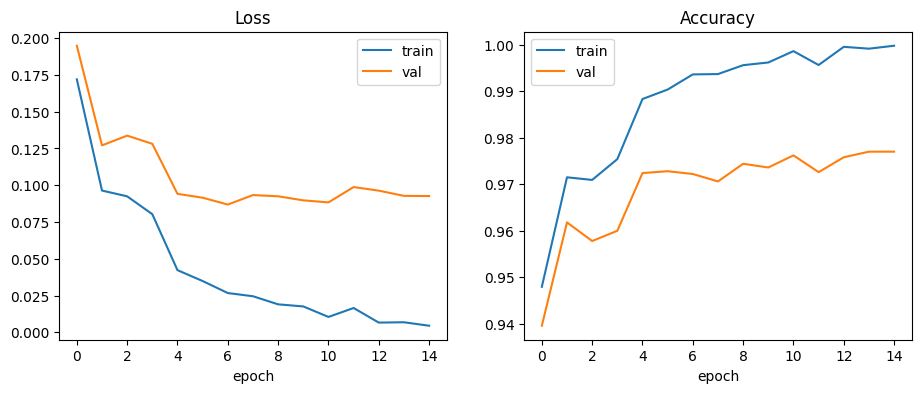

In [16]:
# Learning curves: loss (left) and accuracy (right), train vs validation
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# left panel: loss
ax[0].plot(history['train_loss'], label='train');ax[0].plot(history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
# right panel: accuracy
ax[1].plot(history['train_acc'], label='train'); ax[1].plot(history['val_acc'], label='val')
ax[1].set_title('Accuracy');ax[1].set_xlabel('epoch');ax[1].legend()
plt.show()

### Reading the curves

- Validation accuracy climbs from 93.96% (epoch 1) to **97.70%** at the best checkpoint, while train accuracy reaches 99.98%.
- Validation loss bottoms out at **0.0868 (epoch 7)** and then stops improving while the training loss keeps falling toward 0.005. A growing gap between train and validation is the signature of **overfitting**: the network is starting to memorize the training set.
- The small dips (for example epochs 3 and 12) are noise from plain SGD at a constant learning rate.

---
## 7. Evaluation on the test set

The test set is evaluated **once**, with the best-validation checkpoint (`best_params`). Selecting the checkpoint on validation data and touching the test set only here keeps the final number an honest estimate.

**Result:** test loss **0.0850**, test accuracy **97.65%**, essentially the same as validation accuracy (about 97.7%), so there is no sign of leakage or a validation/test mismatch.

Below: the predictions, then a **confusion matrix** (rows = true digit, columns = predicted digit), then per-class **precision** and **recall**. Overall accuracy can hide a weak class; these expose it.

In [17]:
# Final test-set evaluation, run once, using the best-validation checkpoint (best_params), not the last epoch
test_loss, test_acc = evaluate(X_test, Y_test, y_test, best_params)
print(f'test loss {test_loss:.4f} | test acc {test_acc:.4f}')

test loss 0.0850 | test acc 0.9765


In [18]:
# Predicted class for each test image = index of the highest probability
prob_test , _ = forward(X_test,  best_params)
y_pred = prob_test.argmax(axis=1)

In [19]:
# Confusion matrix: rows = true digit, columns = predicted digit.
# np.add.at accumulates repeated (true, pred) pairs; cm[y_test, y_pred] += 1 would count each pair only once
cm = np.zeros((10, 10), dtype = np.int64)
np.add.at(cm, (y_test, y_pred), 1)

In [20]:
# Per-class metrics from the confusion matrix
# precision = correct predictions of class c / all predictions of c   (column sums)
# recall    = correct predictions of class c / all true samples of c  (row sums)
precision = np.diag(cm) / cm.sum(axis=0)
recall = np.diag(cm) / cm.sum(axis=1)

for c in range(10):
  print(f'digit {c}: precision {precision[c]:.3f} recall {recall[c]:.3f}')

digit 0: precision 0.976 recall 0.987
digit 1: precision 0.994 recall 0.979
digit 2: precision 0.973 recall 0.977
digit 3: precision 0.978 recall 0.979
digit 4: precision 0.977 recall 0.979
digit 5: precision 0.978 recall 0.961
digit 6: precision 0.983 recall 0.976
digit 7: precision 0.976 recall 0.980
digit 8: precision 0.958 recall 0.974
digit 9: precision 0.971 recall 0.972


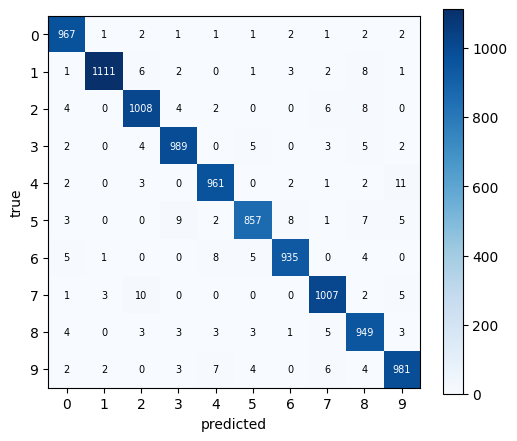

In [21]:
# Heatmap of the confusion matrix: diagonal = correct, off-diagonal = specific confusions
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xlabel('predicted'); plt.ylabel('true'); plt.xticks(range(10)); plt.yticks(range(10))
# write the count inside each cell (white text on dark cells so it stays readable)
for i in range(10):
  for j in range(10):
    plt.text(j, i, cm[i, j], ha='center', va='center',
    color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=7)

plt.show()

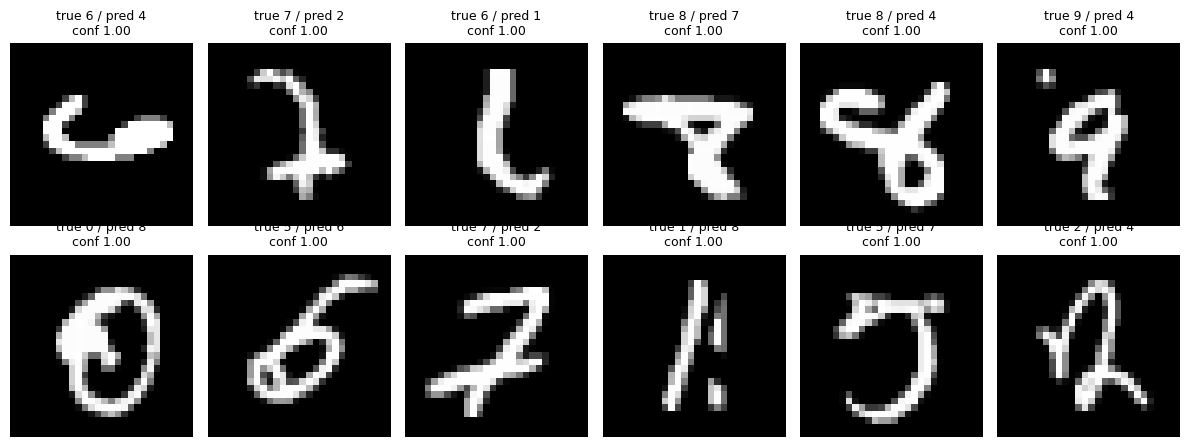

In [22]:
# Show the 12 test images the model got wrong with the HIGHEST confidence
wrong = np.where(y_pred != y_test)[0]            # indices of all misclassified test images
conf = prob_test[wrong, y_pred[wrong]]           # probability given to the (wrong) predicted class
worst = wrong[np.argsort(-conf)[:12]]            # the 12 most confident mistakes

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.ravel(), worst):
  img = (X_test[i] * std + mean).reshape(28, 28)    # undo the standardization to display the original pixels
  ax.imshow(img, cmap='gray')
  ax.set_title(f'true {y_test[i]} / pred {y_pred[i]}\nconf {prob_test[i, y_pred[i]]:.2f}', fontsize=9)
  ax.axis('off')
plt.tight_layout();plt.show()

### Findings

- **Weakest class by recall is 5** (0.961); it leaks into 3, 6 and 8. **Weakest by precision is 8** (0.958): messy digits tend to get dumped into 8.
- **Biggest single confusions:** 4 → 9 (11 images), 7 → 2 (10), 5 → 3 (9). These are visually similar shapes.
- **Strongest:** digit 0 has the best recall (0.987) and digit 1 the best precision (0.994).
- **The most confident mistakes are all at confidence 1.00.** Many of those images are genuinely ambiguous or badly written (a "6" that looks like a blob, a "7" that looks like a "2"), so part of the remaining ~2.3% error is a ceiling set by the data. But the 1.00 confidence also shows the model is **overconfident**, which is typical after driving the training loss to near zero without regularization.

---
## 8. Saving and loading the model

The weights **and** the preprocessing statistics (`mean`, `std`) are saved together in one `.npz` file: at inference time inputs must be standardized exactly as during training, so the model and its preprocessing should never get separated.

The round-trip check reloads the file and re-evaluates on the test set. It reproduces the same numbers as before saving (loss 0.0850, accuracy 0.9765), so saving and loading is lossless.

> The file is written to the Colab working directory, which is deleted when the runtime resets. Copy `mnist_mlp.npz` to Drive if you want to keep it.

In [23]:
# Save weights + preprocessing statistics (mean/std) together: inference must standardize inputs exactly like training.
# NOTE: this writes to the Colab working directory, which is wiped when the runtime resets; copy it to Drive to keep it
np.savez('mnist_mlp.npz', mean=mean, std=std, **best_params)

In [24]:
# Defines load_model(path) -> (params, mean, std)
%run /content/drive/MyDrive/Neural_networks/load_model.py

<Figure size 640x480 with 0 Axes>

In [25]:
# Round-trip check: the reloaded model must reproduce the same test loss / accuracy as before saving
p2, m2, s2 = load_model('mnist_mlp.npz')
print(evaluate(X_test, Y_test, y_test, p2))

(np.float32(0.08499148), np.float64(0.9765))


---
## 9. SGD vs Adam

Same architecture, same seed (identical initial weights and batch order), same 15 epochs; **only the optimizer changes**: Adam with `lr = 1e-3` instead of SGD with `lr = 0.1`. That isolates the effect of the optimizer.

In [26]:
# Same experiment with Adam (lr=1e-3): same seed, init and shuffling, so only the optimizer changes
params = init_params(layers_size, seed=0)
opt = Adam(params, lr=1e-3)     # Adam allocates its moment estimates from the params' shapes
best_params_adam, hist_adam = train(params, opt, X_train, Y_train, y_train,
                                    X_valid, Y_valid, y_valid, epochs=15)

epoch  1 | train_loss 0.1411 acc 0.9587) | val loss 0.1667 acc 0.9506
epoch  2 | train_loss 0.0834 acc 0.9747) | val loss 0.1157 acc 0.9640
epoch  3 | train_loss 0.0649 acc 0.9795) | val loss 0.1061 acc 0.9648
epoch  4 | train_loss 0.0473 acc 0.9853) | val loss 0.0931 acc 0.9690
epoch  5 | train_loss 0.0359 acc 0.9889) | val loss 0.0940 acc 0.9708
epoch  6 | train_loss 0.0284 acc 0.9905) | val loss 0.0929 acc 0.9710
epoch  7 | train_loss 0.0335 acc 0.9887) | val loss 0.1029 acc 0.9708
epoch  8 | train_loss 0.0252 acc 0.9917) | val loss 0.0944 acc 0.9730
epoch  9 | train_loss 0.0199 acc 0.9936) | val loss 0.1027 acc 0.9714
epoch 10 | train_loss 0.0265 acc 0.9906) | val loss 0.1096 acc 0.9704
epoch 11 | train_loss 0.0196 acc 0.9936) | val loss 0.1064 acc 0.9732
epoch 12 | train_loss 0.0269 acc 0.9909) | val loss 0.1333 acc 0.9682
epoch 13 | train_loss 0.0116 acc 0.9963) | val loss 0.1185 acc 0.9764
epoch 14 | train_loss 0.0119 acc 0.9959) | val loss 0.1094 acc 0.9772
epoch 15 | train_los

In [27]:
# Test-set result of the best Adam checkpoint
test_loss_adam, test_acc_adam = evaluate(X_test, Y_test, y_test, best_params_adam)
print(f'test loss {test_loss_adam:.4f} | test acc {test_acc_adam:.4f}')

test loss 0.1005 | test acc 0.9754


### Results: SGD vs Adam

| | SGD (lr 0.1) | Adam (lr 1e-3) |
|---|---|---|
| Epoch-1 validation accuracy | 93.96% | 95.06% |
| Best validation accuracy | 97.70% | 97.72% |
| Lowest validation loss | 0.0868 (epoch 7) | 0.0929 (epoch 6) |
| Final-epoch validation loss | 0.0926 | 0.1269 |
| **Test accuracy** | **97.65%** | **97.54%** |
| Test loss | 0.0850 | 0.1005 |

- **Adam is faster at the start** (about one point ahead after epoch 1) but ends in the same place.
- **The accuracy differences are within noise:** 97.65% vs 97.54% is 11 images out of 10,000, and the standard error of a ~97.6% accuracy on 10,000 samples is about 0.15 points.
- **The loss tells a clearer story:** Adam's validation loss rises from 0.093 to 0.127 while its training loss goes to 0.01, and its test loss is worse than SGD's. It overfits sooner and becomes more overconfident.
- **The optimizer is not the bottleneck.** Both reach the same ceiling because the model is memorizing the training set, which regularization addresses.

---
## 10. Conclusions and next steps

**What was built and verified**

- A 784 → 128 → 64 → 10 MLP in pure NumPy (109,386 parameters), with He initialization, ReLU, a numerically stable softmax and cross-entropy.
- A hand-written backward pass **verified by gradient checking** (relative error below 4e-9), plus a tiny-subset overfit test.
- SGD and Adam optimizers, a mini-batch training loop with validation-based checkpointing, and a save/load round-trip that reproduces the test score.
- **97.65% test accuracy** (SGD) and 97.54% (Adam).

**Main limitation:** overfitting and overconfidence. Training accuracy approaches 100% while validation stalls near 97.7%, and the model's worst mistakes carry confidence 1.00.

**Next steps (not done yet)**

1. **Regularization:** L2 weight decay and dropout, to narrow the train/validation gap and soften the overconfident predictions.
2. **Learning-rate schedule** (for example step or cosine decay) to smooth the noisy later epochs.
3. **Inference on real handwriting:** a `predict(image)` function that crops, centers and resizes a photo into MNIST format with the saved `mean`/`std`.
4. **Compare with a PyTorch equivalent** (same architecture and seed) to cross-check the from-scratch implementation.
5. **Extend to a small CNN built from scratch** (convolution and pooling) for 99%+ accuracy.